# Q1. Which species, if any, are continuing to decline in breeding?

A continuing decline means the species' breeding share fell from 1977–1999 to 2000–2009 **and** again to 2010–2020, with the later and overall drops both clear (95% range below typical).

In [1]:
from pathlib import Path
import textwrap, warnings, logging
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects
from matplotlib.patches import Rectangle, Patch
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import kruskal
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# ---------------- CUSTOMISE HERE ----------------
DATA_PATH = next(p for p in [Path("combined_atlas_des.parquet"), Path("../combined_atlas_des.parquet")] if p.exists())
TRAITS_PATH = Path("species_traits_provisional.csv")
OUTPUT_DIR = Path("outputs")
PDF_NAME = "Q1_Continuing_Declines.pdf"

# Periods. 1977-1999 is the team's agreed early period. The agreed recent period (2000-2020) is split in two
# so we can see whether a decline is still going: 2000-2009 (Millennium Drought years) and 2010-2020 (after it).
PERIODS = {"E": (1977, 1999), "D1": (2000, 2009), "D2": (2010, 2020)}
MIN_EARLY_BREEDING = 30         # breeding records a species needs in 1977-1999
MIN_SIGHTINGS = 150             # sightings a species needs in each of 2000-2009 and 2010-2020
CELL_DEG = 0.5                  # map cell size (about 50 km)
MIN_EXPECTED = 10               # a map cell needs at least this many expected recent breeding records

ZONES = {"NC": "Coast", "CSC": "Coast", "TS": "Coast", "T": "Tablelands", "NTE": "Tablelands",
         "WS": "Inland", "CP": "Inland", "RP": "Inland", "A": "Inland", "MAW": "Inland"}
ZONE_ORDER = ["Coast", "Tablelands", "Inland"]
INTRODUCED = [948, 957, 989, 990, 991, 995, 996, 998, 999]
COLONIAL_WATERBIRDS = [96, 97, 99, 100, 101, 178, 179, 180, 181, 182, 185, 186, 187, 192, 977]  # nest in colonies
# ------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)
PLAB = {k: f"{a}–{b}" for k, (a, b) in PERIODS.items()}

In [2]:
# ---- Chart style (same colour-blind-safe palette as the first client report) ----
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8c8b86", "#e6e5e1", "#ffffff"
BLUE, ORANGE, RED, GREY_PT = "#2a78d6", "#eb6834", "#e34948", "#bdbcb6"
DARK_BLUE, LIGHT_BLUE, LIGHT_RED = "#184f95", "#86b6ef", "#f4a7a6"

mpl.rcParams.update({
    "font.family": ["Segoe UI", "Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "pdf.fonttype": 42, "legend.frameon": False,
})
CHART_SIZE = (8.27, 5.4)        # same shape as the chart area on a PDF page
HALO = [mpl.patheffects.withStroke(linewidth=2.4, foreground="white")]

def headline(fig, title, subtitle):
    fig.text(0.07, 0.975, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.07, 0.915, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)

def show(chart, name):
    fig = plt.figure(figsize=CHART_SIZE)
    chart(fig)
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200)
    plt.show()

def tidy_name(n):
    return n.title() if isinstance(n, str) and n.isupper() else n

def answer(Q):
    display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q["findings"]) +
                     f"\n\n**What it means:** {Q['meaning']}\n\n*Caution: {Q['caveat']}*"))

TOWNS = {"Sydney": (-33.87, 151.21), "Newcastle": (-32.93, 151.78), "Canberra": (-35.28, 149.13),
         "Dubbo": (-32.25, 148.60), "Broken Hill": (-31.95, 141.47), "Wagga Wagga": (-35.12, 147.37),
         "Armidale": (-30.51, 151.67), "Bourke": (-30.09, 145.94), "Griffith": (-34.29, 146.04),
         "Port Macquarie": (-31.43, 152.91), "Lismore": (-28.81, 153.28), "Albury": (-36.08, 146.92),
         "Bathurst": (-33.42, 149.58), "Tamworth": (-31.09, 150.93), "Moree": (-29.47, 149.84),
         "Wollongong": (-34.42, 150.89), "Nowra": (-34.88, 150.60), "Bega": (-36.67, 149.84),
         "Cooma": (-36.24, 149.12), "Goulburn": (-34.75, 149.72), "Orange": (-33.28, 149.10),
         "Mudgee": (-32.60, 149.59), "Coonabarabran": (-31.27, 149.28), "Narrabri": (-30.33, 149.78),
         "Grafton": (-29.69, 152.93), "Coffs Harbour": (-30.30, 153.11), "Taree": (-31.90, 152.46),
         "Forbes": (-33.38, 148.01), "Parkes": (-33.14, 148.17), "Cobar": (-31.50, 145.84),
         "Hay": (-34.51, 144.84), "Deniliquin": (-35.53, 144.96), "Narrandera": (-34.75, 146.55),
         "Young": (-34.31, 148.30), "Queanbeyan": (-35.35, 149.23), "Katoomba": (-33.71, 150.31),
         "Gosford": (-33.43, 151.34), "Maitland": (-32.73, 151.56), "Singleton": (-32.57, 151.17),
         "Muswellbrook": (-32.26, 150.89), "Glen Innes": (-29.74, 151.74), "Tenterfield": (-29.05, 152.02),
         "Inverell": (-29.77, 151.11), "Gunnedah": (-30.98, 150.25), "Walgett": (-30.02, 148.12),
         "Wilcannia": (-31.56, 143.38), "Ivanhoe": (-32.90, 144.30), "Balranald": (-34.64, 143.56),
         "Wentworth": (-34.11, 141.92), "Tibooburra": (-29.43, 142.01), "Nyngan": (-31.56, 147.19),
         "Lithgow": (-33.48, 150.16), "Batemans Bay": (-35.71, 150.18), "Eden": (-37.07, 149.90),
         "Tumut": (-35.30, 148.22), "Kempsey": (-31.08, 152.83), "Ballina": (-28.87, 153.56),
         "Leeton": (-34.55, 146.40), "Condobolin": (-33.09, 147.15), "West Wyalong": (-33.92, 147.21),
         "Warren": (-31.70, 147.83), "Coonamble": (-30.95, 148.39), "Brewarrina": (-29.96, 146.86),
         "Menindee": (-32.39, 142.42), "Jindabyne": (-36.42, 148.62), "Scone": (-32.05, 150.87)}

def nearest_town(lat, lon):
    k = min(TOWNS, key=lambda t: (TOWNS[t][0] - lat) ** 2 + ((TOWNS[t][1] - lon) * np.cos(np.radians(lat))) ** 2)
    dist = 111 * np.hypot(TOWNS[k][0] - lat, (TOWNS[k][1] - lon) * np.cos(np.radians(lat)))
    return k if dist < 15 else f"near {k}"

def nsw_axes(ax):
    ax.set_aspect(1 / np.cos(np.radians(33)))
    ax.set_xlim(140.8, 154); ax.set_ylim(-37.7, -28.0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

def label_towns(ax, towns, size=7.2):
    for t in towns:
        la, lo = TOWNS[t]
        ax.plot(lo, la, "o", ms=2.8, color=INK, zorder=5)
        ax.text(lo + 0.12, la + 0.08, t, fontsize=size, color=INK, zorder=5, path_effects=HALO)


DIV = {"much_less": "#d43d3c", "less": "#f4a7a6", "typical": "#e6e5e1", "more": "#86b6ef", "much_more": "#256abf"}

In [3]:
logging.getLogger("fontTools").setLevel(logging.ERROR)
A4 = (8.27, 11.69)
PAGE_M = 0.7                                  # page margin, inches
ACCENT = BLUE

def _text(fig, y, s, size, weight="normal", color=INK, width=100, x=None, style="normal"):
    for line in textwrap.wrap(s, width=width):
        fig.text((x or PAGE_M) / A4[0], 1 - y / A4[1], line, fontsize=size, fontweight=weight, color=color, va="top",
                 fontstyle=style)
        y += size * 1.42 / 72
    return y

def _label(fig, y, s):
    fig.text(PAGE_M / A4[0], 1 - y / A4[1], s.upper(), fontsize=8.5, fontweight="bold", color=ACCENT, va="top")
    return y + 0.24

def _bullets(fig, y, items, marker_color=ACCENT, size=10, width=96, color=INK):
    for b in items:
        fig.text((PAGE_M + 0.02) / A4[0], 1 - (y - 0.01) / A4[1], "•", fontsize=size + 1, color=marker_color, va="top")
        y = _text(fig, y, b, size, width=width, x=PAGE_M + 0.22, color=color) + 0.07
    return y

def plain_page(pdf, label, title, chart, findings, causes, note, subtitle=None, chart_h=5.0):
    # White page with light typographic structure: label, title, chart, findings, speculation, note
    fig = plt.figure(figsize=A4)
    y = _label(fig, PAGE_M, label)
    y = _text(fig, y, title, 16, "bold", width=62)
    if subtitle:
        y = _text(fig, y + 0.04, subtitle, 11.5, color=INK2)
    fig.add_artist(mpl.lines.Line2D([PAGE_M / A4[0], 1 - PAGE_M / A4[0]], [1 - (y + 0.1) / A4[1]] * 2, color=GRID, lw=1))
    top = y + 0.2
    sub = fig.subfigures(3, 1, height_ratios=[top, chart_h, A4[1] - top - chart_h], hspace=0)[1]
    chart(sub)
    y = top + chart_h + 0.25
    y = _label(fig, y, "Key findings")
    y = _bullets(fig, y, findings) + 0.12
    y = _label(fig, y, "Possible causes  ·  our speculation, not tested here")
    y = _bullets(fig, y, causes, marker_color=MUTED, size=9.4, width=104, color=INK2)
    fig.add_artist(mpl.lines.Line2D([PAGE_M / A4[0], 1 - PAGE_M / A4[0]], [(PAGE_M + 0.42) / A4[1]] * 2, color=GRID, lw=0.8))
    _text(fig, A4[1] - PAGE_M - 0.32, note, 7.8, color=MUTED, width=140)
    pdf.savefig(fig); plt.close(fig)

def show_points(findings, causes):
    display(Markdown("**Key findings**\n" + "\n".join(f"* {p}" for p in findings) +
                     "\n\n**Possible causes (our speculation, not tested here)**\n" + "\n".join(f"* {c}" for c in causes)))

## Data and measure
**Breeding share:** of the Atlas surveys on which a species was recorded, the share with breeding evidence
(surveys only, as agreed). Each species is standardised to the same mix of months in every period, and compared
with the **typical species**, because breeding was recorded less often overall over time. DES (2021–2025) is not
pooled with the Atlas because it recorded breeding differently.

In [4]:
cols = ["source", "sheet_id", "species_id", "common_name", "breeding", "is_collection", "year", "month",
        "klat", "klon", "region", "usable"]
raw = pd.read_parquet(DATA_PATH, columns=cols)
for c in ["source", "sheet_id", "common_name", "region"]:
    raw[c] = raw[c].astype("category")
data = raw[raw["usable"]].copy()
del raw
data["lat"] = -(data["klat"] // 100 + (data["klat"] % 100) / 60)    # grid codes are square centres
data["lon"] = data["klon"] // 100 + (data["klon"] % 100) / 60
data = data[data["lat"].between(-37.7, -28.0) & data["lon"].between(140.9, 153.7)]
names = data.drop_duplicates("species_id").set_index("species_id")["common_name"].astype(str).map(tidy_name)

atlas = data[(data["source"] == "Atlas") & ~data["is_collection"]
             & data["year"].between(PERIODS["E"][0], PERIODS["D2"][1])].copy()
edges = [PERIODS["E"][0] - 1] + [PERIODS[k][1] for k in ["E", "D1", "D2"]]
atlas["period"] = pd.cut(atlas["year"], edges, labels=["E", "D1", "D2"]).astype(str)
atlas["month"] = atlas["month"].astype(int)
atlas["zone"] = atlas["region"].astype(str).map(ZONES)
traits = pd.read_csv(TRAITS_PATH).set_index("species_id")
display(atlas.groupby("period").agg(surveys=("sheet_id", "nunique"), sightings=("breeding", "size"),
                                    breeding_share=("breeding", "mean")).reindex(["E", "D1", "D2"])
        .style.format({"surveys": "{:,.0f}", "sightings": "{:,.0f}", "breeding_share": "{:.2%}"}))

,surveys,sightings,breeding_share
period,,,
E,"131,152","3,171,770",3.56%
D1,"91,090","1,662,915",2.22%
D2,"23,304","693,158",2.01%


## Result

In [5]:
# Month-standardised breeding share for each species and period, using only months seen in all three periods
g = atlas.groupby(["species_id", "period", "month"])["breeding"].agg(["size", "sum"]).reset_index()
g = g.merge(atlas.groupby(["species_id", "month"]).size().rename("wt").reset_index(), on=["species_id", "month"])
g = g[g.groupby(["species_id", "month"])["period"].transform("nunique") == 3]
g["p"] = g["sum"] / g["size"]
g["wp"], g["wv"] = g["wt"] * g["p"], g["wt"] ** 2 * g["p"] * (1 - g["p"]) / g["size"]
agg = g.groupby(["species_id", "period"]).agg(wt=("wt", "sum"), wp=("wp", "sum"), wv=("wv", "sum"),
                                              n=("size", "sum"), b=("sum", "sum"))
agg["p"], agg["v"] = agg["wp"] / agg["wt"], agg["wv"] / agg["wt"] ** 2
r = agg[["p", "v", "n", "b"]].unstack("period")
r = r[(r["b"]["E"] >= MIN_EARLY_BREEDING) & (r["n"][["D1", "D2"]].min(axis=1) >= MIN_SIGHTINGS)]

sp = pd.DataFrame({"name": names.reindex(r.index)})
STEPS = {"step1": ("E", "D1"), "step2": ("D1", "D2"), "overall": ("E", "D2")}
TYPICAL = {}
for k, (a, b) in STEPS.items():
    ratio = r["p"][b] / r["p"][a]
    TYPICAL[k] = ratio.median()
    se = np.sqrt(r["v"][b] / r["p"][b] ** 2 + r["v"][a] / r["p"][a] ** 2)      # delta method, log scale
    rel = np.log(ratio / TYPICAL[k])
    sp[k], sp[k + "_lo"], sp[k + "_hi"] = np.exp(rel), np.exp(rel - 1.96 * se), np.exp(rel + 1.96 * se)
for per in ["E", "D1", "D2"]:
    sp[f"breeding_records_{per}"] = r["b"][per]
sp["introduced"] = sp.index.isin(INTRODUCED)

cont = (sp["step1"] < 1) & (sp["step2_hi"] < 1) & (sp["overall_hi"] < 1)
recovered = (sp["step1_hi"] < 1) & (sp["step2_lo"] > 1)
sp["trend"] = np.select(
    [cont, recovered, sp["step1_hi"] < 1, sp["step2_hi"] < 1, sp["overall_lo"] > 1],
    ["Continuing decline", "Fell, then recovered", "Fell, then steady", "New decline in 2010s", "Increasing"],
    "No clear change")
native = sp[~sp["introduced"]]
cont_sp = native[native["trend"] == "Continuing decline"].sort_values("overall")
counts = native["trend"].value_counts()

sp.sort_values("overall").round(3).to_csv(OUTPUT_DIR / "Q1_breeding_trends.csv")
rec_sp = native[native["trend"] == "Fell, then recovered"].sort_values("step2", ascending=False)
wb = cont_sp[cont_sp.index.isin(COLONIAL_WATERBIRDS)]
bush = cont_sp[~cont_sp.index.isin(COLONIAL_WATERBIRDS)]
display(counts.to_frame("native species"))
print("Typical species change in breeding share:", {k: f"{v - 1:+.0%}" for k, v in TYPICAL.items()})
display(cont_sp[["name", "step1", "step2", "overall", "breeding_records_E", "breeding_records_D2"]].round(2))

,native species
trend,
No clear change,100
Increasing,71
"Fell, then steady",37
New decline in 2010s,20
Continuing decline,13
"Fell, then recovered",8


Typical species change in breeding share: {'step1': '-40%', 'step2': '-23%', 'overall': '-56%'}


,name,step1,step2,overall,breeding_records_E,breeding_records_D2
species_id,,,,,,
186,Intermediate Egret,0.50,0.05,0.03,239,1
180,Straw-necked Ibis,0.47,0.13,0.06,145,1
187,Great Egret,0.75,0.19,0.15,298,6
613,Fuscous Honeyeater,0.97,0.16,0.16,230,2
192,Nankeen Night-Heron,0.72,0.26,0.19,142,3
32,Bar-shouldered Dove,0.65,0.29,0.20,144,6
524,Australian Reed-Warbler,0.58,0.46,0.28,355,9
185,Little Egret,0.76,0.35,0.28,166,6
453,White-throated Gerygone,0.64,0.42,0.28,369,8


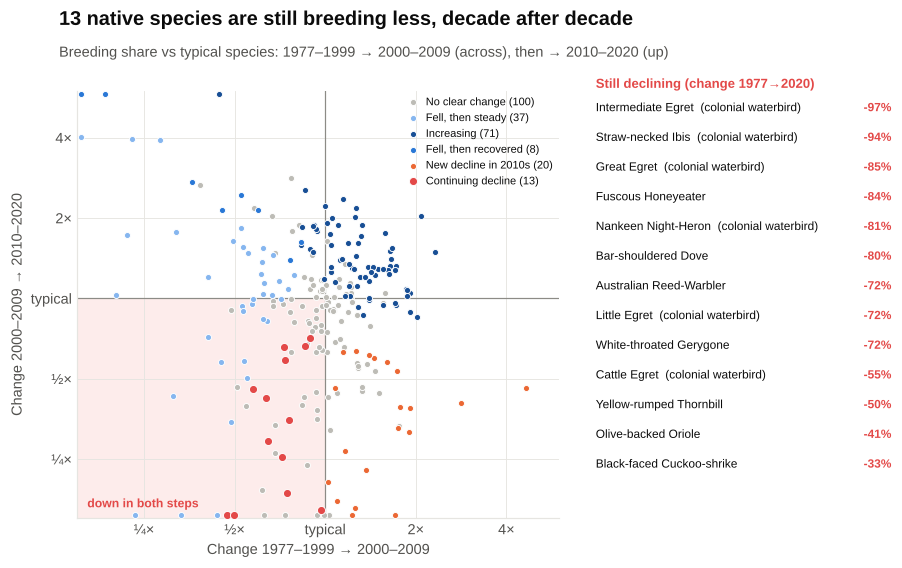

In [6]:
TREND_STYLE = {"Continuing decline": (RED, 3), "Fell, then recovered": (BLUE, 2), "New decline in 2010s": (ORANGE, 2),
               "Fell, then steady": (LIGHT_BLUE, 1), "Increasing": (DARK_BLUE, 1), "No clear change": (GREY_PT, 0)}

def chart_q1(fig):
    headline(fig, f"{len(cont_sp)} native species are still breeding less, decade after decade",
             f"Breeding share vs typical species: {PLAB['E']} → {PLAB['D1']} (across), then → {PLAB['D2']} (up)")
    ax = fig.add_gridspec(1, 1, left=0.09, right=0.62, top=0.84, bottom=0.12).subplots()
    lo, hi = 0.15, 6
    ax.add_patch(Rectangle((lo, lo), 1 - lo, 1 - lo, color="#fdeceb", lw=0, zorder=0))
    ax.axvline(1, color=MUTED, lw=0.8, zorder=1); ax.axhline(1, color=MUTED, lw=0.8, zorder=1)
    for t, (col, z) in sorted(TREND_STYLE.items(), key=lambda kv: kv[1][1]):
        v = native[native["trend"] == t]
        ax.scatter(v["step1"].clip(lo * 1.03, hi / 1.03), v["step2"].clip(lo * 1.03, hi / 1.03),
                   s=28 if z == 3 else 16, color=col, edgecolor="white", lw=0.6, zorder=2 + z, label=f"{t} ({len(v)})")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.minorticks_off()
    ticks, labs = [0.25, 0.5, 1, 2, 4], ["¼×", "½×", "typical", "2×", "4×"]
    ax.set_xticks(ticks, labs); ax.set_yticks(ticks, labs)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel(f"Change {PLAB['E']} → {PLAB['D1']}"); ax.set_ylabel(f"Change {PLAB['D1']} → {PLAB['D2']}")
    ax.text(lo * 1.08, lo * 1.1, "down in both steps", fontsize=8, color=RED, fontweight="bold")
    ax.legend(loc="upper right", fontsize=7.2, handletextpad=0.2, borderaxespad=0.2)
    fig.text(0.66, 0.84, f"Still declining (change {PLAB['E'][:4]}→{PLAB['D2'][-4:]})", fontsize=8.6,
             fontweight="bold", color=RED, va="bottom")
    step = min(0.05, 0.70 / max(len(cont_sp), 1))
    for i, (sid, row) in enumerate(cont_sp.iterrows()):
        y = 0.82 - i * step
        tag = "  (colonial waterbird)" if sid in COLONIAL_WATERBIRDS else ""
        fig.text(0.66, y, row["name"] + tag, fontsize=7.8, va="top", color=INK)
        fig.text(0.985, y, f"{(row['overall'] - 1) * 100:+.0f}%", fontsize=7.8, va="top", ha="right", color=RED,
                 fontweight="bold")

show(chart_q1, "Q1_breeding_continuing_declines")

In [7]:
nm_path = Path("../deeper_insights/outputs/Q1_noisy_miner_by_species.csv")
nm = pd.read_csv(nm_path, index_col=0) if nm_path.exists() else pd.DataFrame(columns=["breed_ratio"])
bush_nm = nm.reindex(bush.index)["breed_ratio"].dropna()
def names_list(df, k=4): return ", ".join(df["name"].head(k))
Q1_POINTS = [
    f"{len(cont_sp)} of {len(native)} native species bred less in both {PLAB['D1']} and {PLAB['D2']}, compared with "
    f"the typical species: {len(wb)} colonial waterbirds ({names_list(wb)}) and {len(bush)} other species, "
    f"mostly woodland birds "
    f"({names_list(bush)}).",
    f"{counts.get('Fell, then recovered', 0)} species fell in {PLAB['D1']} and recovered in {PLAB['D2']} "
    f"(e.g. {names_list(rec_sp, 3)}); {counts.get('Fell, then steady', 0)} fell and then held steady.",
    f"{counts.get('Increasing', 0)} species increased; most species ({counts.get('No clear change', 0)}) show no clear change.",
]
Q1_CAUSES = [
    f"Colonial waterbirds breed in a few big inland colonies when rivers flood. Their breeding stayed low in "
    f"{PLAB['D2']} despite the 2010–12 floods, so less water reaching colony wetlands (river regulation and "
    f"extraction), or fewer Atlas visits to colonies, may be the cause. Testable against aerial waterbird colony counts.",
    "Drought alone does not fit the continuing decliners: the species that recovered after the Millennium Drought "
    "ended show what a drought response looks like, and these did not recover.",
    (f"Noisy Miners are unlikely to explain the woodland birds: in 'Hidden Pressures', their breeding odds with miners "
     f"were {bush_nm.min():.2f}–{bush_nm.max():.2f}× (about the same). Loss of shrub and nest sites in ageing "
     f"woodland remnants is a more likely candidate. Prediction: these species keep declining in DES 2021–25."
     if len(bush_nm) else "Loss of shrub and nest sites in ageing woodland remnants may explain the woodland birds."),
]
Q1_NOTE = (f"Periods: {PLAB['E']} is the team's agreed early period; the recent period is split at 2010 to test "
           f"whether declines continued after the Millennium Drought. Breeding share = sightings with breeding "
           f"evidence, Atlas surveys only, same month mix, vs the typical species. Several decliners have under 10 breeding "
           f"records in {PLAB['D2']}. Table: outputs/Q1_breeding_trends.csv")
show_points(Q1_POINTS, Q1_CAUSES)

**Key findings**
* 13 of 249 native species bred less in both 2000–2009 and 2010–2020, compared with the typical species: 6 colonial waterbirds (Intermediate Egret, Straw-necked Ibis, Great Egret, Nankeen Night-Heron) and 7 other species, mostly woodland birds (Fuscous Honeyeater, Bar-shouldered Dove, Australian Reed-Warbler, White-throated Gerygone).
* 8 species fell in 2000–2009 and recovered in 2010–2020 (e.g. Masked Woodswallow, Black-tailed Native-hen, Beach Stone-curlew); 37 fell and then held steady.
* 71 species increased; most species (100) show no clear change.

**Possible causes (our speculation, not tested here)**
* Colonial waterbirds breed in a few big inland colonies when rivers flood. Their breeding stayed low in 2010–2020 despite the 2010–12 floods, so less water reaching colony wetlands (river regulation and extraction), or fewer Atlas visits to colonies, may be the cause. Testable against aerial waterbird colony counts.
* Drought alone does not fit the continuing decliners: the species that recovered after the Millennium Drought ended show what a drought response looks like, and these did not recover.
* Noisy Miners are unlikely to explain the woodland birds: in 'Hidden Pressures', their breeding odds with miners were 0.90–1.13× (about the same). Loss of shrub and nest sites in ageing woodland remnants is a more likely candidate. Prediction: these species keep declining in DES 2021–25.

## PDF

In [8]:
with PdfPages(OUTPUT_DIR / PDF_NAME) as pdf:
    plain_page(pdf, "Question 1", "Which species, if any, are continuing to decline in breeding?", chart_q1,
               Q1_POINTS, Q1_CAUSES, Q1_NOTE, chart_h=4.8)
    pdf.infodict()["Title"] = "Which species are continuing to decline in breeding?"
print("PDF written to", (OUTPUT_DIR / PDF_NAME).resolve())

PDF written to /home/user/birdbreed/decline_patterns/outputs/Q1_Continuing_Declines.pdf
